# Agglomerative Hierarchical Clustering

**Review 2 - Clustering - no target labels used in fitting**

The 4,009-row used-car dataset is segmented using car age, log price and log mileage.
Training-only preprocessing and five-fold validation choose the model configuration; a separate
20% holdout checks assignment quality. PCA and t-SNE are visualizations, not fitting inputs.

## 1. Imports

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook inside the project or project/notebooks folder.")
sys.path.insert(0, str(ROOT))

from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from src.clustering import *


## 2. Dataset audit and preprocessing

In [2]:
raw, df, train, test = load_data()
display(raw.dtypes.to_frame("dtype").astype(str))
display(raw.isna().sum().to_frame("Missing raw values"))
print("Raw / cleaned / train / holdout:", len(raw), len(df), len(train), len(test))
print("Exact duplicates removed:", len(raw) - len(df))
display(train[["price_usd", "mileage_miles", "car_age"]].describe())
assert set(train.index).isdisjoint(test.index)

Raw / cleaned / train / holdout: 4009 4009 3207 802
Exact duplicates removed: 0


,dtype
brand,object
model,object
model_year,int64
milage,object
fuel_type,object
engine,object
transmission,object
ext_col,object
int_col,object
accident,object


,Missing raw values
brand,0
model,0
model_year,0
milage,0
fuel_type,170
engine,0
transmission,0
ext_col,0
int_col,0
accident,113


,price_usd,mileage_miles,car_age
count,3207.0,3207.0,3207.000000
mean,43125.756782,64942.199563,10.442158
std,51204.51605,52433.516741,6.032533
min,2000.0,100.0,2.000000
25%,17050.0,23319.5,6.000000
50%,31300.0,53500.0,9.000000
75%,49999.0,93985.5,14.000000
max,749950.0,405000.0,52.000000


## 3. Required EDA

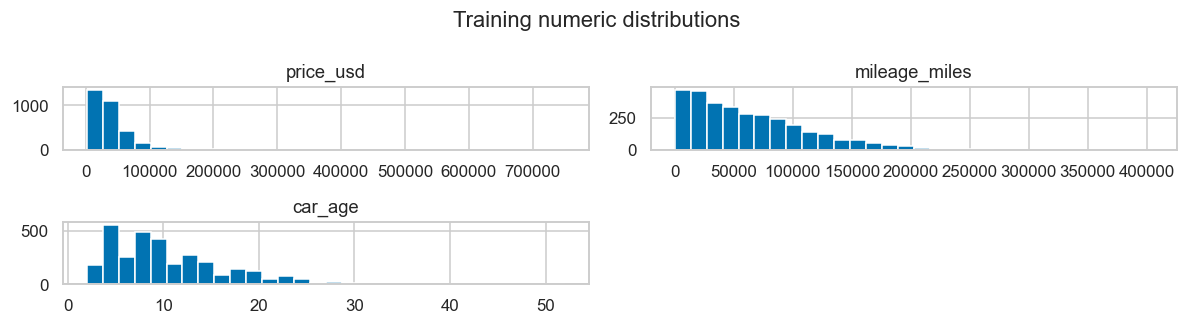

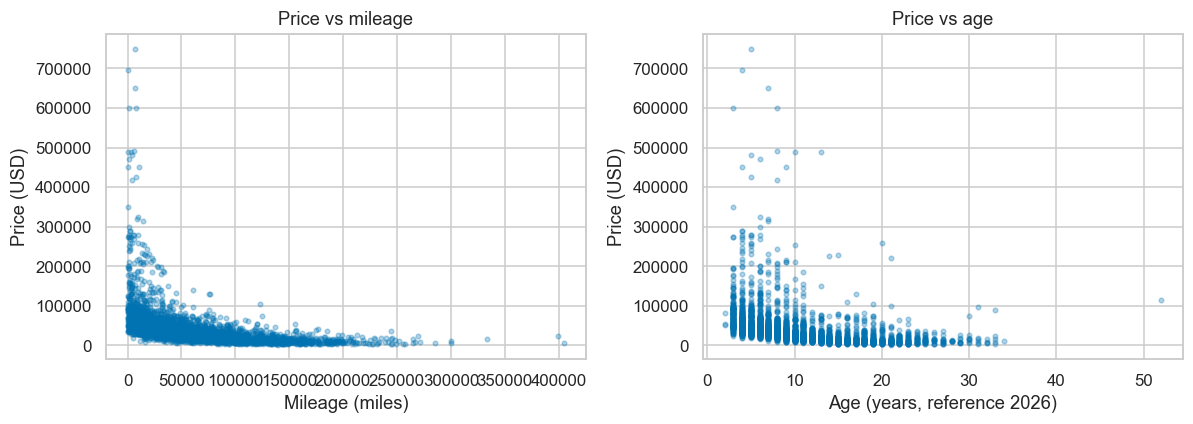

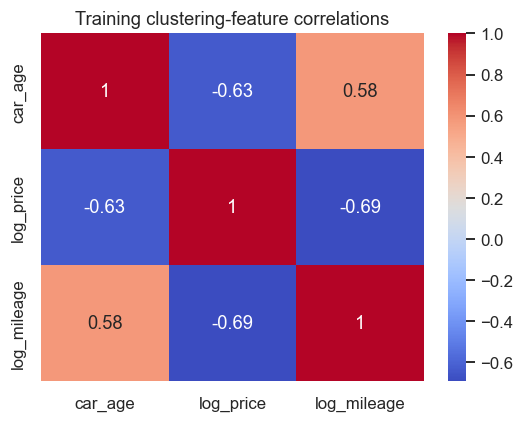

,IQR outliers retained
price_usd,191
mileage_miles,58
car_age,52


In [3]:
train[["price_usd", "mileage_miles", "car_age"]].hist(
    bins=30, figsize=(11, 3)
)
plt.suptitle("Training numeric distributions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(train.mileage_miles, train.price_usd, alpha=0.3, s=9)
axes[0].set(
    xlabel="Mileage (miles)", ylabel="Price (USD)", title="Price vs mileage"
)
axes[1].scatter(train.car_age, train.price_usd, alpha=0.3, s=9)
axes[1].set(
    xlabel="Age (years, reference 2026)",
    ylabel="Price (USD)",
    title="Price vs age",
)
plt.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(5, 4))
sns.heatmap(
    ClusterFeatures().transform(train).corr(), annot=True, cmap="coolwarm", ax=axis
)
axis.set_title("Training clustering-feature correlations")
plt.tight_layout()
plt.show()

numeric = train[["price_usd", "mileage_miles", "car_age"]]
iqr = numeric.quantile(0.75) - numeric.quantile(0.25)
outlier_counts = (
    (numeric < numeric.quantile(0.25) - 1.5 * iqr)
    | (numeric > numeric.quantile(0.75) + 1.5 * iqr)
).sum()
display(outlier_counts.to_frame("IQR outliers retained"))

## 4. Model training and tuning

Candidates are selected using mean five-fold validation silhouette. Higher silhouette and Calinski-Harabasz are better; lower Davies-Bouldin is better.

In [4]:
kind = "agglomerative"
if kind == "kmeans":
    print("Baseline: k=3 | Search: k=2 through 6")
    print("Validation assignment: native K-Means prediction")
else:
    print("Baseline: k=3 with Ward linkage")
    print("Search: k=2 through 6 with Ward, complete and average linkage")
    print("Validation assignment: nearest-training-centroid proxy")

Baseline: k=3 with Ward linkage
Search: k=2 through 6 with Ward, complete and average linkage
Validation assignment: nearest-training-centroid proxy


In [5]:
search_summary, fold_results, best = tune(kind, train)
display(search_summary.sort_values("CV_silhouette", ascending=False))
print("Chosen on training folds only:", best)

output_dir = ROOT / "results" / kind
output_dir.mkdir(parents=True, exist_ok=True)
fold_results.to_csv(output_dir / "cv_fold_results.csv", index=False)

Chosen on training folds only: {'k': 2, 'linkage': 'ward'}


,k,linkage,CV_silhouette,CV_silhouette_std,CV_Davies_Bouldin,CV_Calinski_Harabasz,valid_folds,min_represented_clusters,eligible
0,2,average,0.443144,0.057472,0.616109,68.541974,3,1,False
2,2,ward,0.407265,0.013249,0.881820,570.715496,5,2,True
1,2,complete,0.399943,0.017229,0.875750,510.390396,5,2,True
4,3,complete,0.392341,0.015392,0.871280,483.397578,5,2,False
3,3,average,0.378347,0.031474,0.818288,186.720217,5,2,False
7,4,complete,0.369590,0.027328,0.860118,512.693895,5,3,False
5,3,ward,0.366295,0.026444,0.898613,582.174710,5,3,True
10,5,complete,0.343930,0.023696,0.941014,493.640420,5,4,False
9,5,average,0.338247,0.044007,0.820805,308.839939,5,4,False
8,4,ward,0.328765,0.019949,0.967116,545.849958,5,4,True


## 5. Evaluation

In [6]:
comparison, fitted, prep, X, X_holdout, pca, profiles = fit_compare(
    kind, train, test, search_summary, best
)
display(comparison.round(4))

metric_columns = [
    "Silhouette",
    "Davies_Bouldin",
    "Calinski_Harabasz",
    "CV_silhouette",
    "Holdout_Silhouette",
]
display(
    (comparison.loc[1, metric_columns] - comparison.loc[0, metric_columns]).to_frame(
        "After minus before"
    )
)
display(profiles)

,Model,Stage,k,linkage,Silhouette,Davies_Bouldin,Calinski_Harabasz,CV_silhouette,CV_silhouette_std,Holdout_Silhouette,Holdout_Davies_Bouldin,Holdout_Calinski_Harabasz
0,Agglomerative,Before tuning,3,ward,0.3595,0.8799,2622.7525,0.3663,0.0264,0.3800,0.9105,708.7527
1,Agglomerative,After tuning,2,ward,0.3951,0.8755,2161.4716,0.4073,0.0132,0.4243,0.8506,680.4945


,After minus before
Silhouette,0.035584
Davies_Bouldin,-0.004325
Calinski_Harabasz,-461.280936
CV_silhouette,0.04097
Holdout_Silhouette,0.044248


,cars,median_price_usd,median_mileage_miles,median_age
cluster,,,,
0,2427,38436.0,39192.0,7.0
1,780,11500.0,112000.0,18.0


## 6. Required visualizations and cluster interpretation

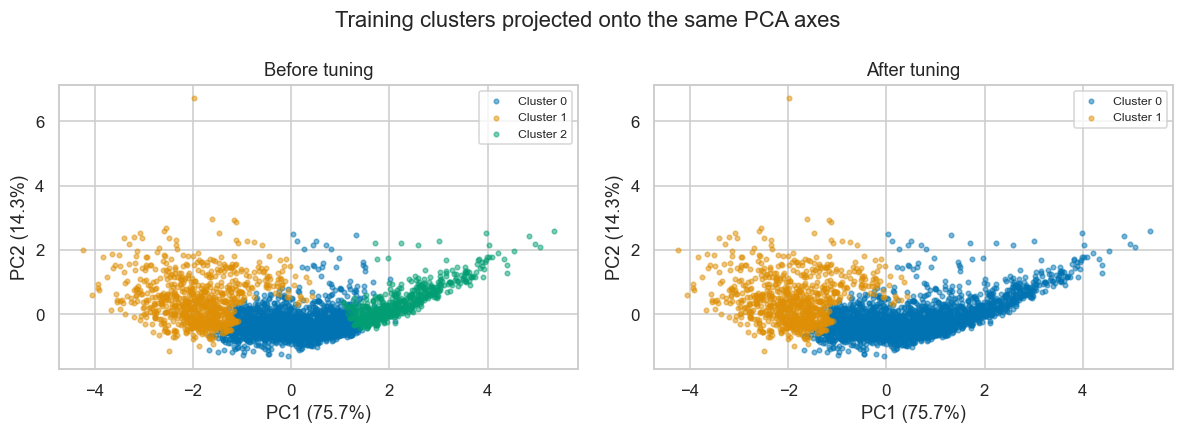

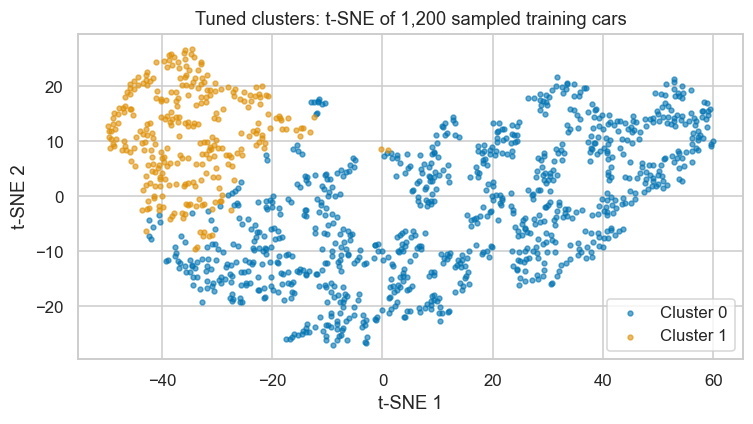

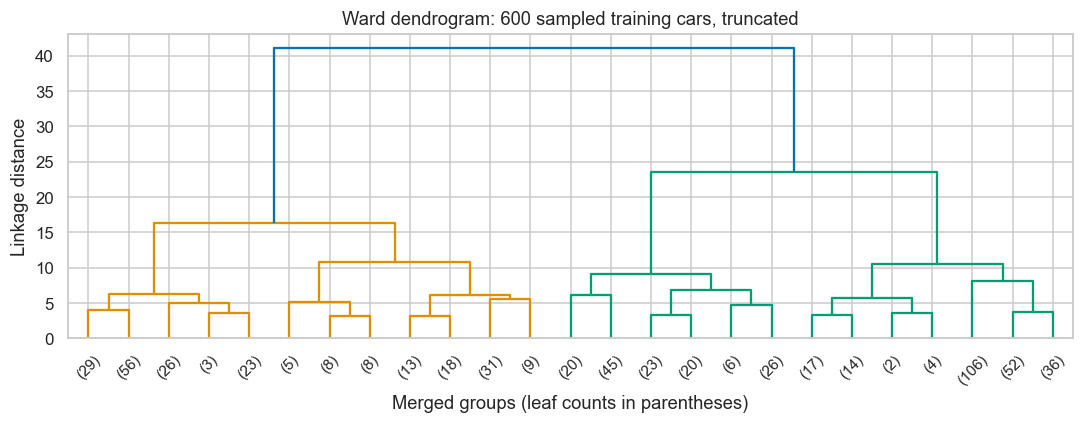

,Diesel,E85 Flex Fuel,Gasoline,Hybrid,Plug-In Hybrid,not supported,–
cluster,,,,,,,
0,0.034,0.033,0.851,0.063,0.013,0.001,0.005
1,0.021,0.053,0.878,0.018,0.001,0.000,0.030


In [7]:
plot_clusters(kind, fitted, X, pca)
display(
    pd.read_csv(output_dir / "fuel_type_profile.csv", index_col=0).round(3)
)

## 7. Observation / Interpretation

Complete these observations using the executed evidence:

- Describe the age, mileage and price profile of each cluster.
- Explain whether the elbow or dendrogram supports the selected number of clusters.
- Compare silhouette, Davies-Bouldin and Calinski-Harabasz before and after tuning.
- Discuss the three-feature limitation and the arbitrary nature of cluster numbers.
- For hierarchical clustering, explain the centroid-proxy limitation for unseen cars.
- Treat t-SNE as a visualization only and do not describe clusters as known ground-truth classes.